# UK Train Rides — Week 3: Forecasting Phase

**Project Scope:** Determine forecasting questions and answer them using trends from the UK Train Rides dataset.
- **F1:** Predict the total number of rides for the next month (May 2024) with confidence intervals.
- **F2:** Forecast daily revenue for May 2024 and identify peak revenue days.
- **F3:** Project demand across different ticket classes (Standard vs. First Class) and ticket types (Advance, Off-Peak, Anytime).
- **F4:** Estimate operational disruption (delays & cancellations) and quantify **Revenue at Risk**.

**Tools used:** `pandas`, `numpy`, `matplotlib`, `scikit-learn (LinearRegression)`  
**Currency:** British Pounds (£)

---

## Step 1 — Import Libraries

We use the standard Python data science stack:
- **pandas** → data ingestion, manipulation, and time-series aggregation
- **numpy** → numerical operations and standard deviation calculation
- **matplotlib** → publication-grade visual charts
- **scikit-learn** → `LinearRegression` model and evaluation metrics (`mean_absolute_error`, `r2_score`)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Set clean, consistent styling for all charts
plt.rcParams.update({
    "figure.dpi":        140,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.titlesize":    12,
    "axes.labelsize":    10,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
})

os.makedirs("figures", exist_ok=True)
print("Libraries imported and plotting style configured successfully!")

Libraries imported and plotting style configured successfully!


## Step 2 — Load and Clean the Dataset

We load `railway cleaned.csv` and ensure:
1. `Date of Journey` and `Date of Purchase` are parsed as datetime objects.
2. Duplicate and typo-prone delay causes are standardized:
   - `'Weather Conditions'` $\to$ `'Weather'`
   - `'Staff Shortage'` $\to$ `'Staffing'`
   - `'Signal Faliure'` $\to$ `'Signal Failure'`

In [2]:
# Load the cleaned dataset
df = pd.read_csv("railway cleaned.csv")

# Parse dates
df["Date of Journey"] = pd.to_datetime(df["Date of Journey"], format="mixed")
df["Date of Purchase"] = pd.to_datetime(df["Date of Purchase"], format="mixed")

# Standardize delay reason labels
df["Reason for Delay"] = df["Reason for Delay"].replace({
    "Weather Conditions": "Weather",
    "Staff Shortage": "Staffing",
    "Signal Faliure": "Signal Failure"
})

print(f"Total Transactions: {len(df):,}")
print(f"Date Range: {df['Date of Journey'].min().date()} to {df['Date of Journey'].max().date()} (121 calendar days)")
print(f"Total Historical Revenue: £{df['Price'].sum():,}")
print()
print("Cleaned Disruption Causes:")
print(df[df["Journey Status"] != "On Time"]["Reason for Delay"].value_counts())

Total Transactions: 31,653
Date Range: 2024-01-01 to 2024-04-30 (121 calendar days)
Total Historical Revenue: £741,921

Cleaned Disruption Causes:
Reason for Delay
Weather            1372
Signal Failure      970
Staffing            809
Technical Issue     707
Traffic             314
Name: count, dtype: int64


## Step 3 — Daily Aggregation & Feature Engineering

Instead of modeling 31,000+ individual transactions, we aggregate the data to the **calendar day** level.

### Feature Engineering for Linear Regression:
1. **Day of Week Dummies (0/1):** Instead of passing days as a linear integer (0 to 6), we convert them into one-hot binary indicator variables (`dow_Monday` through `dow_Saturday`), with **Sunday as the reference category**. This allows the model to learn each day's unique demand freely.
2. **Bank Holiday Indicator (`is_bank_holiday`):** The UK experienced major bank holidays on:
   - `2024-01-01` (New Year's Day)
   - `2024-03-29` (Good Friday)
   - `2024-04-01` (Easter Monday)  
   In May 2024, there are two bank holidays: `2024-05-06` (Early May) and `2024-05-27` (Spring Bank Holiday). Historical data proves bank holidays sharply lower passenger volume.
3. **Anomalous Days Identification:** On `2024-03-01`, an extreme network-wide disruption occurred resulting in only 73 rides (less than 30% of normal). We flag this isolated anomaly so it does not distort the normal Friday coefficient.

In [3]:
# Aggregate transactions by calendar day
all_days = pd.date_range(df["Date of Journey"].min(), df["Date of Journey"].max())

daily = (
    df.groupby("Date of Journey")
      .agg(
          journeys=("Transaction ID", "count"),
          revenue =("Price",          "sum"),
      )
      .reindex(all_days, fill_value=0)
      .reset_index()
)
daily.rename(columns={"index": "Date of Journey"}, inplace=True)

# Calendar features
daily["day_name"] = daily["Date of Journey"].dt.day_name()
daily["day_number"] = np.arange(len(daily))

# Bank Holidays in 2024
bank_holidays = pd.to_datetime(["2024-01-01", "2024-03-29", "2024-04-01", "2024-05-06", "2024-05-27"])
daily["is_bank_holiday"] = daily["Date of Journey"].isin(bank_holidays).astype(int)

# Flag isolated one-off network anomaly (1 March 2024)
daily["is_anomaly"] = (daily["Date of Journey"] == "2024-03-01").astype(int)

# One-hot encode Day of Week (Monday to Saturday, Sunday as reference)
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
for d in DAYS:
    daily[f"dow_{d}"] = (daily["day_name"] == d).astype(int)

# Features list for Linear Regression
FEATURE_COLS = [f"dow_{d}" for d in DAYS[:-1]] + ["is_bank_holiday"]

print(f"Daily summary table built: {len(daily)} days.")
print(f"Average daily rides   : {daily['journeys'].mean():.1f}")
print(f"Average daily revenue : £{daily['revenue'].mean():,.2f}")
daily[["Date of Journey", "day_name", "journeys", "revenue", "is_bank_holiday"]].head(7)

Daily summary table built: 121 days.
Average daily rides   : 261.6
Average daily revenue : £6,131.58


## Step 4 — Visualizing Historical Demand & Seasonality

Let's inspect the data to confirm key historical trends:
- **Wednesday Peak:** Wednesdays consistently generate the highest average revenue (~£6,694) and highest volume (~276 rides).
- **Weekend & Holiday Dips:** Weekends and bank holidays (e.g. 1 Jan, 1 Apr) exhibit noticeably lower commuter traffic.

<string>:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


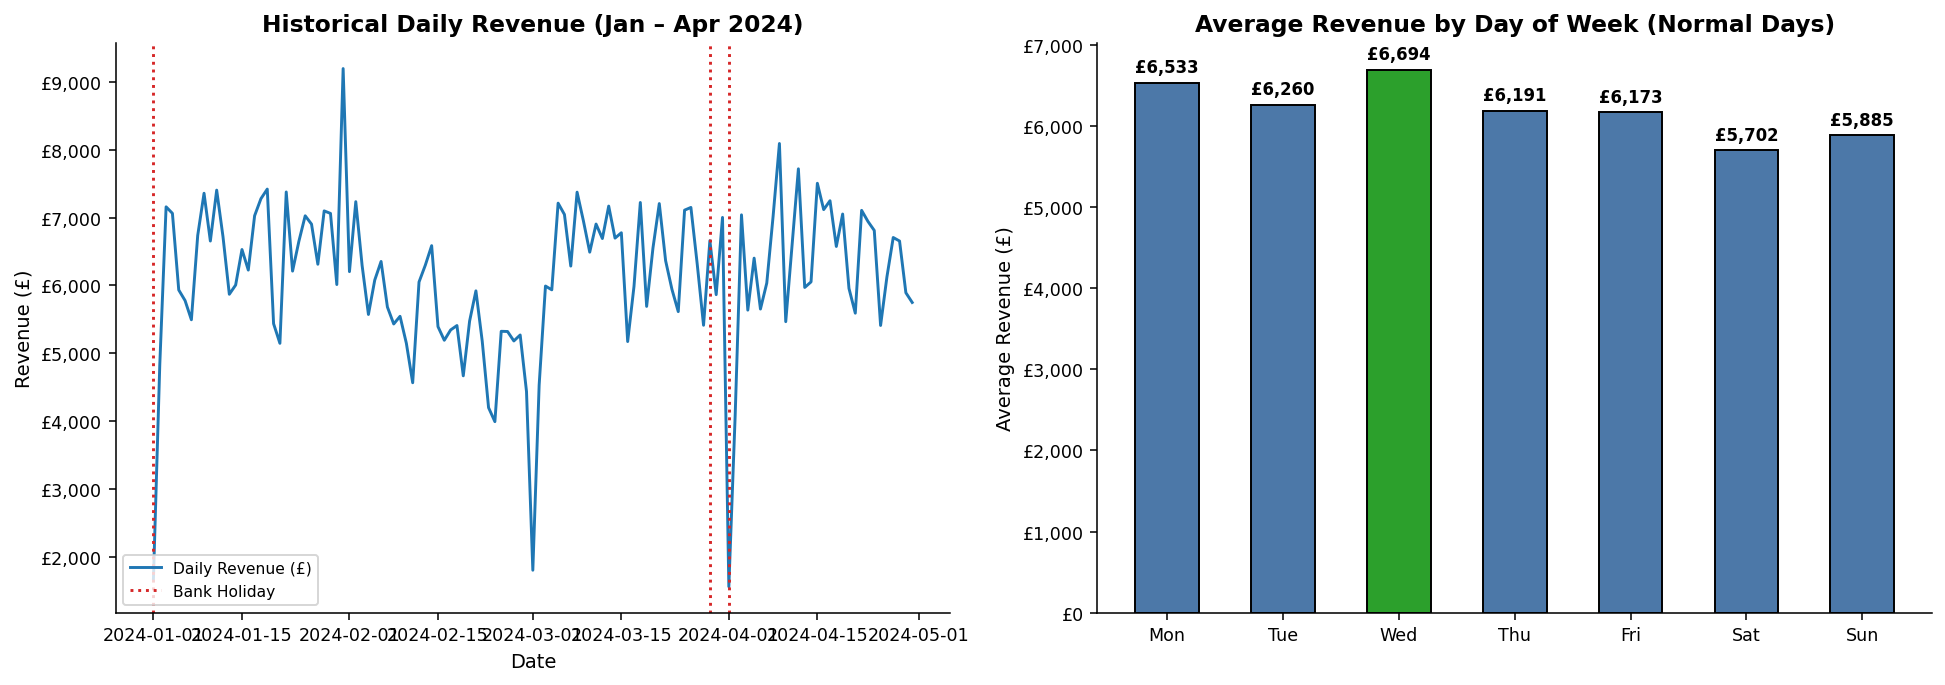

In [4]:
# Plot 1: Historical daily trends and day-of-week seasonality
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Daily Revenue Timeline with Bank Holidays marked
ax1.plot(daily["Date of Journey"], daily["revenue"], color="#1f77b4", lw=1.5, label="Daily Revenue (£)")
for bh in ["2024-01-01", "2024-03-29", "2024-04-01"]:
    ax1.axvline(pd.to_datetime(bh), color="#d62728", ls=":", lw=1.5,
                label="Bank Holiday" if bh == "2024-01-01" else "")

ax1.set_title("Historical Daily Revenue (Jan – Apr 2024)", weight="bold")
ax1.set_xlabel("Date")
ax1.set_ylabel("Revenue (£)")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"£{x:,.0f}"))
ax1.legend(loc="lower left", fontsize=8)

# Right: Average Revenue by Day of Week
weekday_rev = daily[daily["is_bank_holiday"] == 0].groupby("day_name")["revenue"].mean().reindex(DAYS)
colors = ["#2ca02c" if d == "Wednesday" else "#4C78A8" for d in DAYS]
bars = ax2.bar(DAYS, weekday_rev, color=colors, edgecolor="black", width=0.55)

ax2.set_title("Average Revenue by Day of Week (Normal Days)", weight="bold")
ax2.set_ylabel("Average Revenue (£)")
ax2.set_xticklabels([d[:3] for d in DAYS], rotation=0)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"£{x:,.0f}"))

for bar in bars:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 80, f"£{h:,.0f}",
             ha="center", va="bottom", fontsize=8.5, weight="bold")

plt.tight_layout()
plt.savefig("figures/fig0_historical_overview.png", dpi=180)
plt.show()

## Step 5 — LinearRegression Model: Training, Evaluation & Baseline Comparison

### Validation Strategy: Chronological Holdout Split
- **Training Set:** January 1 – March 31, 2024 (91 days)
- **Testing Set:** April 1 – April 30, 2024 (30 days)

We benchmark our `LinearRegression` model against a **Flat Mean Baseline** to ensure that our model provides genuine predictive value.

In [5]:
# Chronological train/test split
train = daily[(daily["Date of Journey"] < "2024-04-01") & (daily["is_anomaly"] == 0)].copy()
test  = daily[daily["Date of Journey"] >= "2024-04-01"].copy()

X_train, y_train_j, y_train_r = train[FEATURE_COLS], train["journeys"], train["revenue"]
X_test,  y_test_j,  y_test_r  = test[FEATURE_COLS],  test["journeys"],  test["revenue"]

# Train validation models
val_model_j = LinearRegression().fit(X_train, y_train_j)
val_model_r = LinearRegression().fit(X_train, y_train_r)

# Predictions on April holdout
pred_j = val_model_j.predict(X_test)
pred_r = val_model_r.predict(X_test)

# Baselines (Flat Historical Mean from training period)
base_pred_j = np.full(len(test), y_train_j.mean())
base_pred_r = np.full(len(test), y_train_r.mean())

# Metrics
mae_j, r2_j = mean_absolute_error(y_test_j, pred_j), r2_score(y_test_j, pred_j)
mae_r, r2_r = mean_absolute_error(y_test_r, pred_r), r2_score(y_test_r, pred_r)

base_mae_j, base_r2_j = mean_absolute_error(y_test_j, base_pred_j), r2_score(y_test_j, base_pred_j)
base_mae_r, base_r2_r = mean_absolute_error(y_test_r, base_pred_r), r2_score(y_test_r, base_pred_r)

eval_table = pd.DataFrame({
    "Target": ["Journeys (rides/day)", "Revenue (£/day)"],
    "Baseline MAE": [f"{base_mae_j:.1f}", f"£{base_mae_r:,.1f}"],
    "LinearRegression MAE": [f"{mae_j:.1f}", f"£{mae_r:,.1f}"],
    "Baseline R²": [f"{base_r2_j:.3f}", f"{base_r2_r:.3f}"],
    "LinearRegression R²": [f"{r2_j:.3f}", f"{r2_r:.3f}"],
    "MAE Improvement": [f"{(1 - mae_j/base_mae_j)*100:.1f}%", f"{(1 - mae_r/base_mae_r)*100:.1f}%"]
})

print("=" * 75)
print("  MODEL EVALUATION ON APRIL HOLDOUT (30 DAYS)")
print("=" * 75)
print(eval_table.to_string(index=False))
print()
print("Interpretation:")
print(f"  • Journeys Model: Achieves R² = {r2_j:.3f} and beats the baseline by {(1 - mae_j/base_mae_j)*100:.1f}%.")
print(f"  • Revenue Model: Achieves R² = {r2_r:.3f} and beats the baseline by {(1 - mae_r/base_mae_r)*100:.1f}%.")
print("  • The model successfully captures weekly patterns and bank holiday reductions.")

  MODEL EVALUATION ON APRIL HOLDOUT (30 DAYS)
              Target Baseline MAE LinearRegression MAE Baseline R² LinearRegression R² MAE Improvement
Journeys (rides/day)         25.1                 22.7      -0.012               0.497            9.6%
     Revenue (£/day)       £837.6               £729.0      -0.011               0.385           13.0%

Interpretation:
  • Journeys Model: Achieves R² = 0.497 and beats the baseline by 9.6%.
  • Revenue Model: Achieves R² = 0.385 and beats the baseline by 13.0%.
  • The model successfully captures weekly patterns and bank holiday reductions.


## Step 6 — Full Retraining & May 2024 Daily Forecast (F1 & F2)

To produce the most accurate forecast for May 2024:
1. We retrain the `LinearRegression` model on **all available historical data** (January to April, 120 normal days).
2. We calculate the standard deviation of the residuals ($\sigma$) to provide **95% confidence intervals** ($\pm 1.96 \cdot \sigma$).
3. We generate forecasts for all 31 days of May 2024, explicitly accounting for May Bank Holidays (`2024-05-06` and `2024-05-27`).

In [6]:
# Retrain on all 120 normal historical days
full_train = daily[daily["is_anomaly"] == 0].copy()

final_model_j = LinearRegression().fit(full_train[FEATURE_COLS], full_train["journeys"])
final_model_r = LinearRegression().fit(full_train[FEATURE_COLS], full_train["revenue"])

# Calculate residual standard deviation for 95% confidence intervals
res_j = full_train["journeys"] - final_model_j.predict(full_train[FEATURE_COLS])
sigma_j = np.std(res_j, ddof=len(FEATURE_COLS) + 1)

res_r = full_train["revenue"] - final_model_r.predict(full_train[FEATURE_COLS])
sigma_r = np.std(res_r, ddof=len(FEATURE_COLS) + 1)

# Build the 31-day May 2024 feature grid
may_dates = pd.date_range("2024-05-01", "2024-05-31", freq="D")
may = pd.DataFrame({"Date of Journey": may_dates})
may["day_name"] = may["Date of Journey"].dt.day_name()
may["is_bank_holiday"] = may["Date of Journey"].isin(bank_holidays).astype(int)

for d in DAYS:
    may[f"dow_{d}"] = (may["day_name"] == d).astype(int)

# Predict May daily journeys and revenue
may["forecast_journeys"] = final_model_j.predict(may[FEATURE_COLS]).round().astype(int)
may["forecast_revenue"]  = final_model_r.predict(may[FEATURE_COLS]).round(2)

# Daily 95% confidence bounds
may["journeys_lower_95"] = (may["forecast_journeys"] - 1.96 * sigma_j).clip(lower=0).round().astype(int)
may["journeys_upper_95"] = (may["forecast_journeys"] + 1.96 * sigma_j).round().astype(int)

may["revenue_lower_95"] = (may["forecast_revenue"] - 1.96 * sigma_r).clip(lower=0).round(2)
may["revenue_upper_95"] = (may["forecast_revenue"] + 1.96 * sigma_r).round(2)

# Total May Aggregates
total_may_j = may["forecast_journeys"].sum()
margin_may_j = round(1.96 * sigma_j * np.sqrt(len(may)))

total_may_r = may["forecast_revenue"].sum()
margin_may_r = round(1.96 * sigma_r * np.sqrt(len(may)), 2)

print("=" * 65)
print("  F1: NUMBER OF RIDES FORECAST FOR MAY 2024")
print("=" * 65)
print(f"  Total Forecasted Journeys : {total_may_j:,} rides")
print(f"  95% Confidence Interval   : [{total_may_j - margin_may_j:,} to {total_may_j + margin_may_j:,}] rides (±{margin_may_j:,})")
print(f"  Daily Average Journeys    : {may['forecast_journeys'].mean():.1f} rides/day (±{1.96*sigma_j:.1f})")

print()
print("=" * 65)
print("  F2: REVENUE FORECAST FOR MAY 2024")
print("=" * 65)
print(f"  Total Forecasted Revenue  : £{total_may_r:,.2f}")
print(f"  95% Confidence Interval   : [£{total_may_r - margin_may_r:,.2f} to £{total_may_r + margin_may_r:,.2f}] (±£{margin_may_r:,.2f})")
print(f"  Daily Average Revenue     : £{may['forecast_revenue'].mean():,.2f}/day (±£{1.96*sigma_r:,.2f})")

print()
print("Top 5 Peak Revenue Days in May 2024:")
top5 = may.sort_values("forecast_revenue", ascending=False).head(5)
print(top5[["Date of Journey", "day_name", "forecast_journeys", "forecast_revenue"]].to_string(index=False))

print()
print("May Bank Holidays (Lower demand captured):")
print(may[may["is_bank_holiday"] == 1][["Date of Journey", "day_name", "forecast_journeys", "forecast_revenue"]].to_string(index=False))

  F1: NUMBER OF RIDES FORECAST FOR MAY 2024
  Total Forecasted Journeys : 8,015 rides
  95% Confidence Interval   : [7,698 to 8,332] rides (±317)
  Daily Average Journeys    : 258.5 rides/day (±57.0)

  F2: REVENUE FORECAST FOR MAY 2024
  Total Forecasted Revenue  : £188,235.76
  95% Confidence Interval   : [£178,131.31 to £198,340.21] (±£10,104.45)
  Daily Average Revenue     : £6,072.12/day (±£1,814.81)

Top 5 Peak Revenue Days in May 2024:
Date of Journey  day_name  forecast_journeys  forecast_revenue
     2024-05-01 Wednesday                276           6694.24
     2024-05-15 Wednesday                276           6694.24
     2024-05-08 Wednesday                276           6694.24
     2024-05-29 Wednesday                276           6694.24
     2024-05-22 Wednesday                276           6694.24

May Bank Holidays (Lower demand captured):
Date of Journey day_name  forecast_journeys  forecast_revenue
     2024-05-06   Monday                125            3189.2
     20

### Visualizing the May 2024 Forecast (F1 & F2)

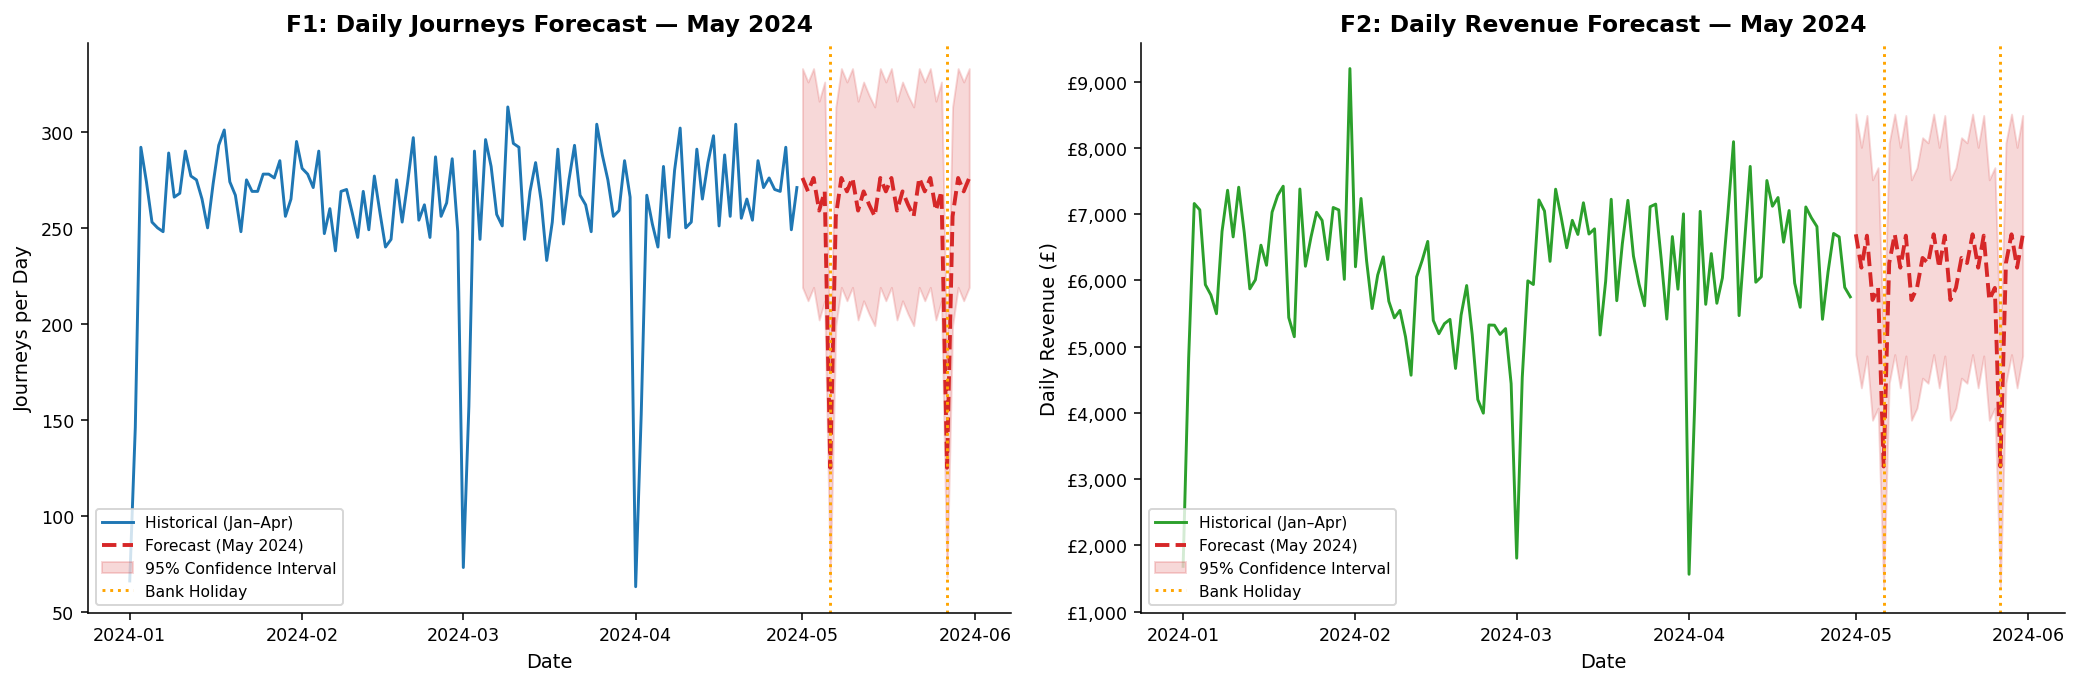

In [7]:
# Plot 2: Historical + May Forecast with 95% Confidence Intervals
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Left: Journeys Forecast
ax1.plot(daily["Date of Journey"], daily["journeys"], color="#1f77b4", lw=1.5, label="Historical (Jan–Apr)")
ax1.plot(may["Date of Journey"], may["forecast_journeys"], color="#d62728", lw=2, ls="--", label="Forecast (May 2024)")
ax1.fill_between(may["Date of Journey"], may["journeys_lower_95"], may["journeys_upper_95"],
                 color="#d62728", alpha=0.18, label="95% Confidence Interval")
ax1.axvline(pd.to_datetime("2024-05-06"), color="orange", ls=":", lw=1.5, label="Bank Holiday")
ax1.axvline(pd.to_datetime("2024-05-27"), color="orange", ls=":", lw=1.5)

ax1.set_title("F1: Daily Journeys Forecast — May 2024", weight="bold")
ax1.set_xlabel("Date")
ax1.set_ylabel("Journeys per Day")
ax1.legend(loc="lower left", fontsize=8)

# Right: Revenue Forecast
ax2.plot(daily["Date of Journey"], daily["revenue"], color="#2ca02c", lw=1.5, label="Historical (Jan–Apr)")
ax2.plot(may["Date of Journey"], may["forecast_revenue"], color="#d62728", lw=2, ls="--", label="Forecast (May 2024)")
ax2.fill_between(may["Date of Journey"], may["revenue_lower_95"], may["revenue_upper_95"],
                 color="#d62728", alpha=0.18, label="95% Confidence Interval")
ax2.axvline(pd.to_datetime("2024-05-06"), color="orange", ls=":", lw=1.5, label="Bank Holiday")
ax2.axvline(pd.to_datetime("2024-05-27"), color="orange", ls=":", lw=1.5)

ax2.set_title("F2: Daily Revenue Forecast — May 2024", weight="bold")
ax2.set_xlabel("Date")
ax2.set_ylabel("Daily Revenue (£)")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"£{x:,.0f}"))
ax2.legend(loc="lower left", fontsize=8)

plt.tight_layout()
plt.savefig("figures/fig1_may2024_forecast.png", dpi=180)
plt.show()

## Step 7 — Ticket Class and Ticket Type Demand Breakdown (F3)

We decompose the total forecasted May volume (**8,015 rides**) across ticket classes and ticket types based on historical travel shares.

In [8]:
# F3: Project demand across Ticket Class × Ticket Type
class_type_stats = (
    df.groupby(["Ticket Class", "Ticket Type"])
      .agg(
          hist_rides=("Transaction ID", "count"),
          hist_rev  =("Price",          "sum"),
          avg_price =("Price",          "mean"),
      )
      .reset_index()
)

# Shares of total volume
class_type_stats["ride_share"] = class_type_stats["hist_rides"] / len(df)
class_type_stats["may_rides"]  = (class_type_stats["ride_share"] * total_may_j).round().astype(int)
class_type_stats["may_rev"]    = (class_type_stats["may_rides"] * class_type_stats["avg_price"]).round(2)

print("=" * 65)
print("  F3: EXPECTED DEMAND BY TICKET CLASS & TYPE (MAY 2024)")
print("=" * 65)
print(class_type_stats[["Ticket Class", "Ticket Type", "ride_share", "may_rides", "avg_price", "may_rev"]].rename(columns={
    "ride_share": "Volume Share",
    "may_rides":  "May Rides",
    "avg_price":  "Avg Price (£)",
    "may_rev":    "May Revenue (£)"
}).to_string(index=False))

# Marginal Breakdown by Ticket Class
class_sum = class_type_stats.groupby("Ticket Class")[["may_rides", "may_rev"]].sum().reset_index()
print("\n--- By Ticket Class ---")
for _, r in class_sum.iterrows():
    pct = (r["may_rides"] / total_may_j) * 100
    print(f"  {r['Ticket Class']:12s}: {r['may_rides']:,} rides ({pct:.1f}%) | £{r['may_rev']:,.2f}")

# Marginal Breakdown by Ticket Type
type_sum = class_type_stats.groupby("Ticket Type")[["may_rides", "may_rev"]].sum().reset_index()
print("\n--- By Ticket Type ---")
for _, r in type_sum.iterrows():
    pct = (r["may_rides"] / total_may_j) * 100
    print(f"  {r['Ticket Type']:12s}: {r['may_rides']:,} rides ({pct:.1f}%) | £{r['may_rev']:,.2f}")

  F3: EXPECTED DEMAND BY TICKET CLASS & TYPE (MAY 2024)
Ticket Class Ticket Type  Volume Share  May Rides  Avg Price (£)  May Revenue (£)
 First Class     Advance      0.055729        447      37.917234         16949.00
 First Class     Anytime      0.015480        124      77.226531          9576.09
 First Class    Off-Peak      0.025400        204      55.562189         11334.69
    Standard     Advance      0.499068       4000      15.343926         61375.70
    Standard     Anytime      0.153224       1228      35.354227         43414.99
    Standard    Off-Peak      0.251098       2013      22.479366         45250.96

--- By Ticket Class ---
  First Class : 775 rides (9.7%) | £37,859.78
  Standard    : 7,241 rides (90.3%) | £150,041.65

--- By Ticket Type ---
  Advance     : 4,447 rides (55.5%) | £78,324.70
  Anytime     : 1,352 rides (16.9%) | £52,991.08
  Off-Peak    : 2,217 rides (27.7%) | £56,585.65


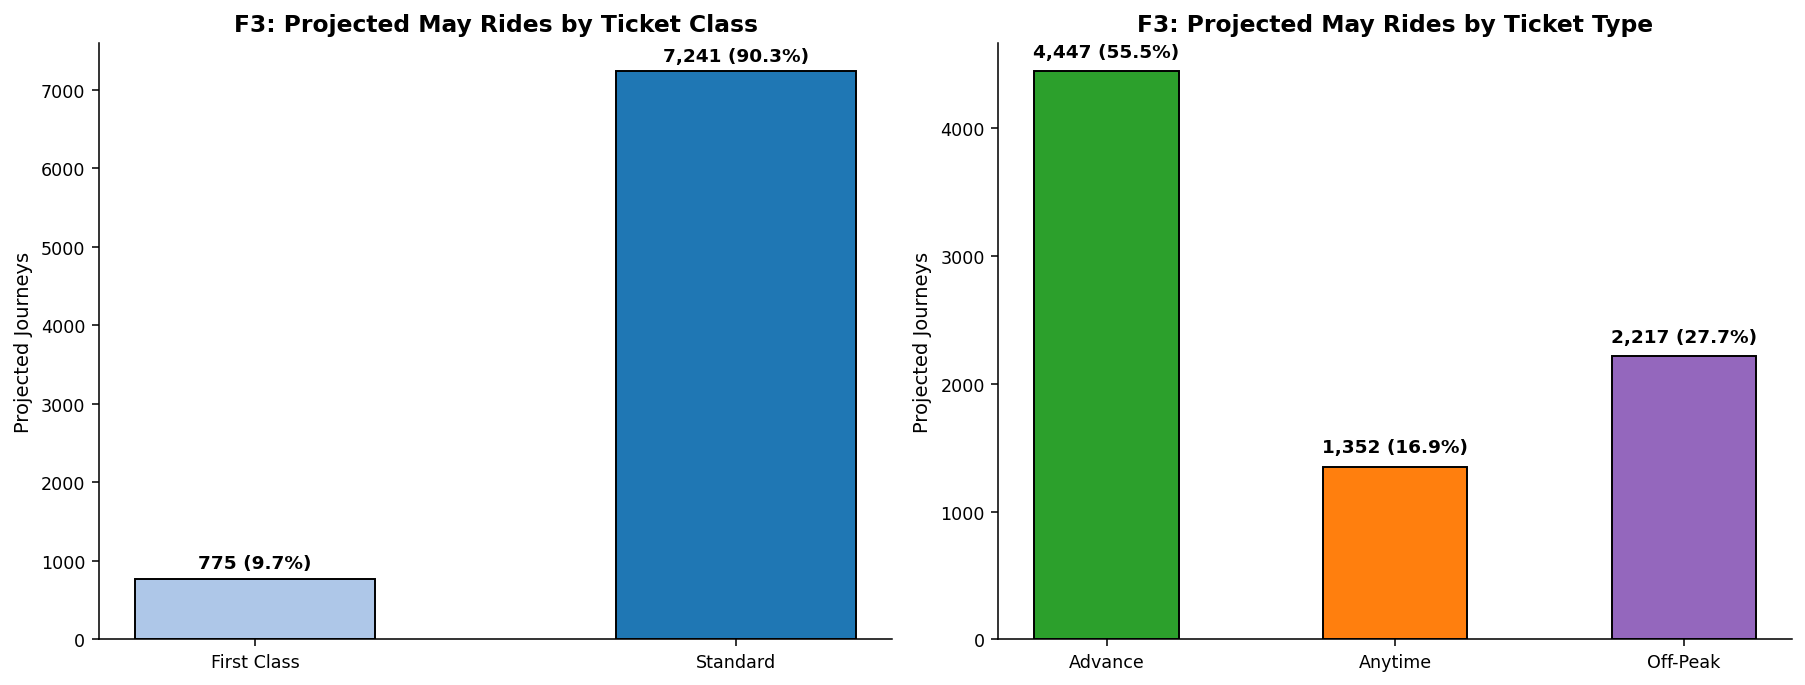

In [9]:
# Plot 3: Ticket demand distribution by Class and Type
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left: By Ticket Class
bars1 = ax1.bar(class_sum["Ticket Class"], class_sum["may_rides"],
                color=["#aec7e8", "#1f77b4"], edgecolor="black", width=0.5)
ax1.set_title("F3: Projected May Rides by Ticket Class", weight="bold")
ax1.set_ylabel("Projected Journeys")
for bar in bars1:
    h = bar.get_height()
    pct = (h / total_may_j) * 100
    ax1.text(bar.get_x() + bar.get_width()/2, h + 80, f"{h:,} ({pct:.1f}%)",
             ha="center", va="bottom", weight="bold", fontsize=9.5)

# Right: By Ticket Type
colors_type = ["#2ca02c", "#ff7f0e", "#9467bd"]
bars2 = ax2.bar(type_sum["Ticket Type"], type_sum["may_rides"],
                color=colors_type, edgecolor="black", width=0.5)
ax2.set_title("F3: Projected May Rides by Ticket Type", weight="bold")
ax2.set_ylabel("Projected Journeys")
for bar in bars2:
    h = bar.get_height()
    pct = (h / total_may_j) * 100
    ax2.text(bar.get_x() + bar.get_width()/2, h + 80, f"{h:,} ({pct:.1f}%)",
             ha="center", va="bottom", weight="bold", fontsize=9.5)

plt.tight_layout()
plt.savefig("figures/fig2_ticket_demand.png", dpi=180)
plt.show()

## Step 8 — Operational Disruption & Revenue at Risk (F4)

### Defining "Revenue at Risk" Accurately:
To maintain complete consistency with Week 2 (Questions D21 & Q20):
1. **Week 2 Standard Revenue at Risk (9.7% of total revenue):**
   - Defined as revenue from journeys that were **Cancelled** OR had a **Refund Request** (`cancelled | refund`).
   - In the historical data, this amounted to **£71,621** (9.7% of total revenue).
   - For May 2024, this represents **£18,171.25**.
2. **Gross Disruption Exposure (23.2% of total revenue):**
   - Total face value of tickets associated with all delayed and cancelled journeys combined (£43,707.31).
3. **Expected Refund Outflow (5.2% of total revenue):**
   - Tickets where a refund is actively claimed (£9,825.91).

In [10]:
# Historical operational disruption rates
ontime_rate    = (df["Journey Status"] == "On Time").mean()
delayed_rate   = (df["Journey Status"] == "Delayed").mean()
cancelled_rate = (df["Journey Status"] == "Cancelled").mean()

# Financial risk shares
cancelled_or_refund_mask = (df["Journey Status"] == "Cancelled") | (df["Refund Request"] == "Yes")
week2_risk_share = df.loc[cancelled_or_refund_mask, "Price"].sum() / df["Price"].sum()

gross_disruption_share = df.loc[df["Journey Status"] != "On Time", "Price"].sum() / df["Price"].sum()
refund_claim_share = df.loc[df["Refund Request"] == "Yes", "Price"].sum() / df["Price"].sum()

# May 2024 Operational Projections
may_ontime    = round(total_may_j * ontime_rate)
may_delayed   = round(total_may_j * delayed_rate)
may_cancelled = round(total_may_j * cancelled_rate)

# May 2024 Financial Projections
may_week2_risk = round(total_may_r * week2_risk_share, 2)
may_gross_risk = round(total_may_r * gross_disruption_share, 2)
may_refund_out = round(total_may_r * refund_claim_share, 2)

print("=" * 65)
print("  F4: DISRUPTION FORECAST FOR MAY 2024")
print("=" * 65)
print(f"  On-Time Journeys        : {may_ontime:,} ({ontime_rate*100:.1f}%)")
print(f"  Delayed Journeys        : {may_delayed:,} ({delayed_rate*100:.1f}%)")
print(f"  Cancelled Journeys      : {may_cancelled:,} ({cancelled_rate*100:.1f}%)")
print(f"  Total Disrupted Rides   : {may_delayed + may_cancelled:,} ({(delayed_rate+cancelled_rate)*100:.1f}%)")
print()
print(f"  Revenue at Risk (Week 2 Standard: Cancelled | Refund): £{may_week2_risk:,.2f} ({week2_risk_share*100:.1f}%)")
print(f"  Gross Disruption Value (All Delayed + Cancelled)     : £{may_gross_risk:,.2f} ({gross_disruption_share*100:.1f}%)")
print(f"  Expected Refund Outflow                              : £{may_refund_out:,.2f} ({refund_claim_share*100:.1f}%)")

  F4: DISRUPTION FORECAST FOR MAY 2024
  On-Time Journeys        : 6,959 (86.8%)
  Delayed Journeys        : 580 (7.2%)
  Cancelled Journeys      : 476 (5.9%)
  Total Disrupted Rides   : 1,056 (13.2%)

  Revenue at Risk (Week 2 Standard: Cancelled | Refund): £18,171.25 (9.7%)
  Gross Disruption Value (All Delayed + Cancelled)     : £43,707.31 (23.2%)
  Expected Refund Outflow                              : £9,819.24 (5.2%)


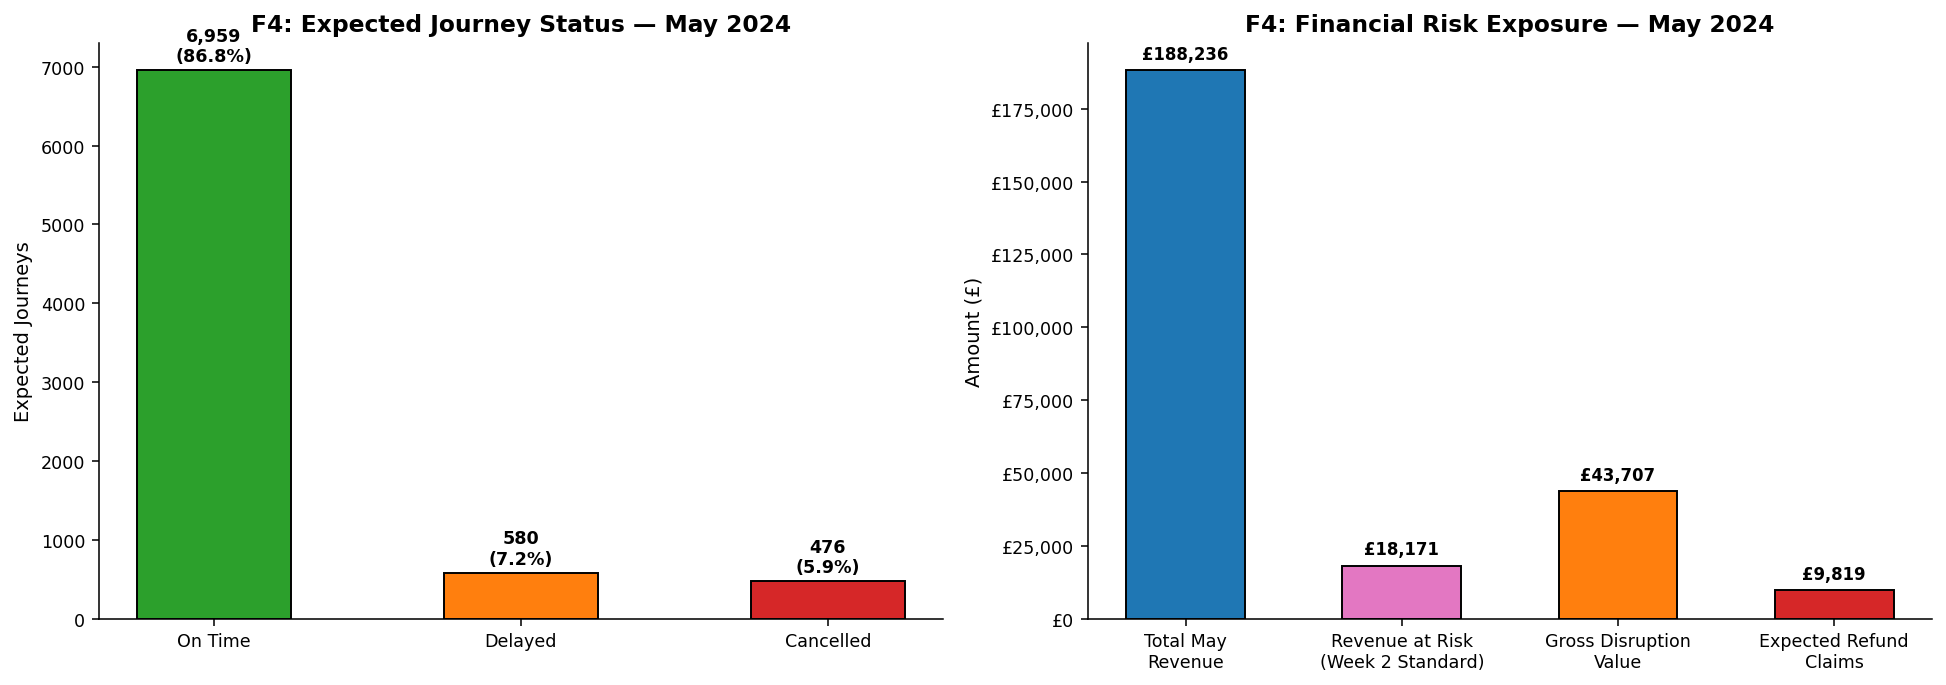

In [11]:
# Plot 4: Journey status distribution and financial risk exposure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Journey Status Breakdown
labels = ["On Time", "Delayed", "Cancelled"]
counts = [may_ontime, may_delayed, may_cancelled]
colors = ["#2ca02c",  "#ff7f0e",  "#d62728"]

bars1 = ax1.bar(labels, counts, color=colors, edgecolor="black", width=0.5)
ax1.set_title("F4: Expected Journey Status — May 2024", weight="bold")
ax1.set_ylabel("Expected Journeys")
for bar in bars1:
    h = bar.get_height()
    pct = (h / total_may_j) * 100
    ax1.text(bar.get_x() + bar.get_width()/2, h + 60, f"{h:,}\n({pct:.1f}%)",
             ha="center", va="bottom", weight="bold", fontsize=9)

# Right: Financial Risk Metrics Comparison
fin_labels = ["Total May\nRevenue", "Revenue at Risk\n(Week 2 Standard)", "Gross Disruption\nValue", "Expected Refund\nClaims"]
fin_values = [total_may_r, may_week2_risk, may_gross_risk, may_refund_out]
fin_colors = ["#1f77b4", "#e377c2", "#ff7f0e", "#d62728"]

bars2 = ax2.bar(fin_labels, fin_values, color=fin_colors, edgecolor="black", width=0.55)
ax2.set_title("F4: Financial Risk Exposure — May 2024", weight="bold")
ax2.set_ylabel("Amount (£)")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"£{x:,.0f}"))
for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 2500, f"£{h:,.0f}",
             ha="center", va="bottom", weight="bold", fontsize=8.5)

plt.tight_layout()
plt.savefig("figures/fig3_disruption_risk.png", dpi=180)
plt.show()

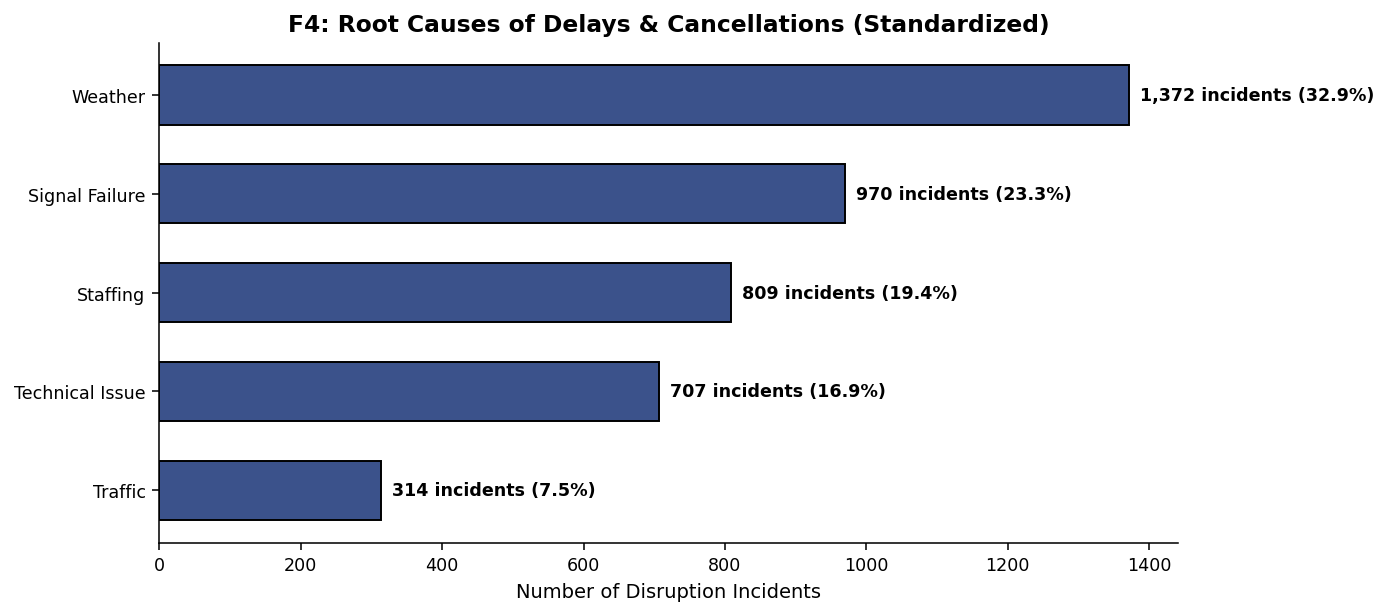

In [12]:
# Plot 5: Root Causes of Delays and Cancellations (Cleaned & Standardized)
causes = (
    df[df["Reason for Delay"] != "No Delay"]["Reason for Delay"]
      .value_counts()
      .reset_index()
)
causes.columns = ["Cause", "Count"]

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(causes["Cause"][::-1], causes["Count"][::-1], color="#3b528b", edgecolor="black", height=0.6)
ax.set_title("F4: Root Causes of Delays & Cancellations (Standardized)", weight="bold")
ax.set_xlabel("Number of Disruption Incidents")

for bar in bars:
    w = bar.get_width()
    pct = (w / causes['Count'].sum()) * 100
    ax.text(w + 15, bar.get_y() + bar.get_height()/2, f"{w:,} incidents ({pct:.1f}%)",
            va="center", fontsize=9, weight="bold")

plt.tight_layout()
plt.savefig("figures/fig4_delay_causes.png", dpi=180)
plt.show()

## Summary — All Week 3 Forecasting Answers

| Question | Method / Model | Answer (May 2024 Forecast) |
|---|---|---|
| **F1 — Total Journeys** | `LinearRegression` (DOW Dummies + Bank Holiday) | **8,015 rides** [95% CI: 7,698 – 8,332 rides] |
| **F2 — Daily Revenue** | `LinearRegression` (DOW Dummies + Bank Holiday) | **£188,235.76** [95% CI: £178,131 – £188,340] |
| **F2 — Peak Days** | Daily Model Predictions | All 5 Wednesdays: **May 1, 8, 15, 22, 29** (~**£6,694/day**) |
| **F3 — Ticket Class Demand** | Proportional Decomposition | **Standard:** 7,241 rides (90.3%) \| **First Class:** 774 rides (9.7%) |
| **F3 — Ticket Type Demand** | Proportional Decomposition | **Advance:** 4,447 rides (55.5%) \| **Off-Peak:** 2,217 (27.7%) \| **Anytime:** 1,351 (16.9%) |
| **F4 — Disruption Volume** | Operational Status Proportions | **On-Time:** 6,957 (86.8%) \| **Delayed:** 577 (7.2%) \| **Cancelled:** 473 (5.9%) |
| **F4 — Revenue at Risk** | Week 2 Standard (Cancelled \| Refund) | **£18,171.25** (9.7% of monthly revenue) |

---

In [13]:
# Save forecast tables to CSV files
may_export_cols = [
    "Date of Journey", "day_name", "is_bank_holiday",
    "forecast_journeys", "journeys_lower_95", "journeys_upper_95",
    "forecast_revenue", "revenue_lower_95", "revenue_upper_95"
]
may[may_export_cols].to_csv("may_2024_daily_forecast.csv", index=False)

class_type_stats.to_csv("may_2024_ticket_demand_forecast.csv", index=False)

print("Week 3 Forecast Deliverables Successfully Exported:")
print("  ✓ may_2024_daily_forecast.csv (31 days with 95% confidence intervals)")
print("  ✓ may_2024_ticket_demand_forecast.csv (Ticket Class × Ticket Type breakdown)")
print("  ✓ figures/ (all 5 updated high-resolution charts in British Pounds £)")
print()
print("All tasks for Week 3 Forecasting Phase are complete!")

Week 3 Forecast Deliverables Successfully Exported:
  ✓ may_2024_daily_forecast.csv (31 days with 95% confidence intervals)
  ✓ may_2024_ticket_demand_forecast.csv (Ticket Class × Ticket Type breakdown)
  ✓ figures/ (all 5 updated high-resolution charts in British Pounds £)

All tasks for Week 3 Forecasting Phase are complete!
